In [1]:
import sys
sys.path.append('../src/')
from xpcs import *
from plotting import *
from autocorrelations import *
import cv2
from scipy.special import erfinv
import pyopencl as cl
from pathlib import Path
import matplotlib.cm as cm
import json
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
#from cmcrameri import cm
import matplotlib as mpl

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import ListedColormap
from matplotlib.colors import LinearSegmentedColormap

from scipy.interpolate import interp1d
from scipy.signal import detrend

import colorsys

%matplotlib inline

In [2]:
Scans = np.array([219,334,552,579,709,779,796,868])
Temps = np.array([298,305,325,345,365,385,405,350])
max_tau = np.array([44,176,176,224,128,864,768,384])

color_list = np.array(['#074a54','#1c94b0','#6abce7','#9c86e3','#ee8bb6','#f27086','#da499d','#7e8285'])
marker_list = np.array(['v','s','o','*','p','D','>','H'])



def lighten_hls(hex_color, factor):
    r, g, b = mcolors.to_rgb(hex_color)
    h, l, s = colorsys.rgb_to_hls(r, g, b)
    return colorsys.hls_to_rgb(h, min(1, l * factor), s)

shades = [lighten_hls(color_list[0], f) for f in np.linspace(1.0, 1.8, 5)]

In [3]:
### Figure Settings ###

plt.rcParams['font.sans-serif'] = ['Helvetica']

legend_ax_font = 12+4
ax_label_font = 16+4
ax_title_font = 18+4

minor_tick_length = 5
major_tick_length = 8
minor_tick_width = 0.75
major_tick_width = 1.0

fig_size = (8,5)

nps_custom = LinearSegmentedColormap.from_list(
  'nps_custom', [
    (0.00, '#000000'),
    (0.07, '#342c7a'), #0.12
    (0.20, '#a43479'), #25
    (0.55, '#d74444'),
    (0.78, '#f3de80'),
    (1.00, '#ffffff'),
], N=256
)

In [ ]:
G2s = []
G2_errs = []
DELAYS = []
DQ = []
Cs = []
CEXT = []

AA = []
TAUS = []
BETAS = []
TwoTime = []
TwoTime_extent = []





# Define the path to the configuration file
config_path = Path("../configs/config_NPS_example.json")

# Open and load the JSON configuration file
with open(config_path, "r") as file:
    config = json.load(file)
    #json_str = json.loads(jsonString, strict=False)

### Output Directory ###
figure_path = config_path.parent.parent / config.get("Figures")
figure_path.mkdir(parents=True, exist_ok=True)


for s in Scans:
    base_path = Path(config.get("Base")) 
    results_path = Path(config.get("Results"))
    file = base_path / Path(config.get(f"{s}")) / results_path / Path(config.get(f"{s}_results"))

    with h5py.File(file, 'r') as DATA:
        g2s = DATA['XPCS/G2_Results'][:]
        g2_errs = DATA['XPCS/G2_error'][:]
        delays = DATA['XPCS/delays'][:]
        dQ = DATA['XPCS/dQ'][:]
        As = DATA['XPCS/As'][:]

        # Cs = DATA['XPCS/Cs'][:]
        taus = DATA['XPCS/taus'][:]
        betas = DATA['XPCS/betas'][:]
        taus_err = DATA['XPCS/taus_err'][:]
        betas_err = DATA['XPCS/betas_err'][:]
        
        #TwoTime
        TwoTime = DATA['XPCS/TwoTime'][:]
        #print(TwoTime.shape)
        TwoTime_extent = DATA['XPCS/TwoTime_extent'][:]

        G2s.append(g2s)
        G2_errs.append(g2_errs)
        DELAYS.append(delays)
        DQ.append(dQ)

        Cs.append(TwoTime)
        CEXT.append(TwoTime_extent)

        AA.append(As)
        TAUS.append(taus)
        BETAS.append(betas)


        

/Users/eriklamb/projects/na3ps4-strain-glass-xpcs/notebooks/../src/xpcs.py:171: RuntimeWarning: invalid value encountered in power
  return 1+A*np.exp(-(t/tt)**b)**2


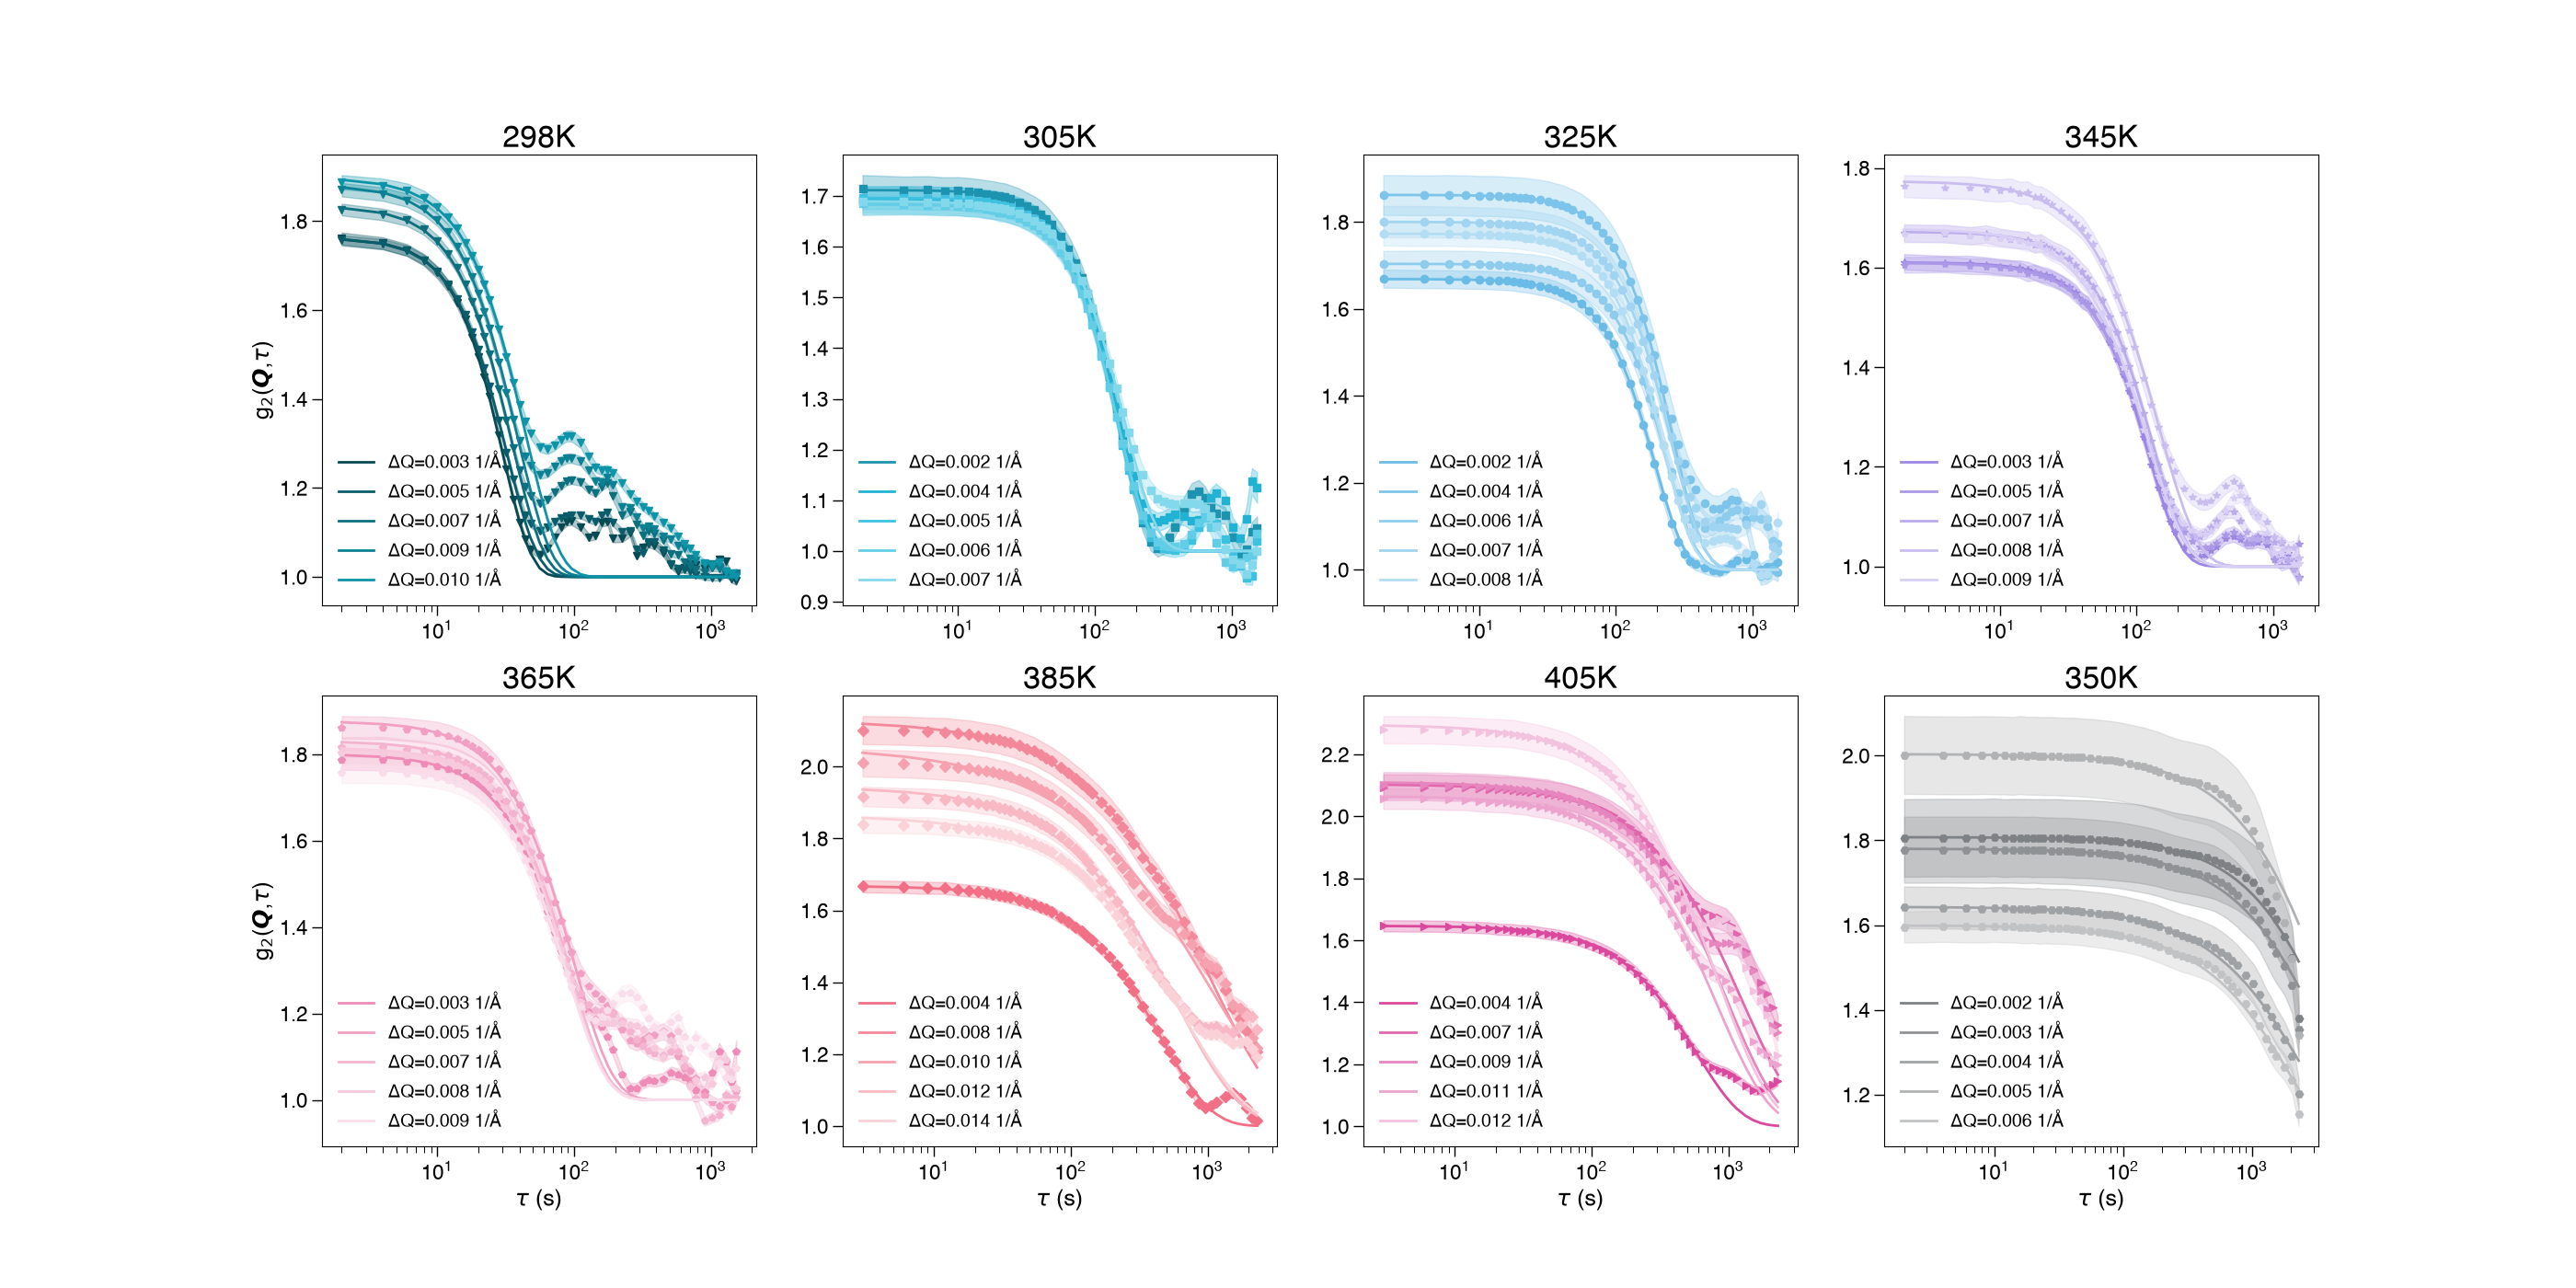

In [5]:
%matplotlib widget
I = 0

fig,ax = plt.subplots(2,4,figsize=(28,14))



#Per scan
taus_scan = []
betas_scan = []
contrasts_scan = []

taus_err_scan = []
betas_err_scan = []
contrasts_err_scan = []

shade_max = [2.0,1.8,1.25,1.25,1.25,1.3,1.5,1.5]
J = 0
for I in range(len(Scans)):

    #Per Q ring
    taus = []
    betas = []
    contrasts = []

    taus_err = []
    betas_err = []
    contrasts_err = []

    shades = [lighten_hls(color_list[I], f) for f in np.linspace(1.0, shade_max[I], 5)]

    for g2,g2_err,A,tt,b,q,sh in zip(G2s[I],G2_errs[I],AA[I],TAUS[I],BETAS[I],DQ[I],shades):
        mask = np.where(DELAYS[I][0] < max_tau[I])

        popt, cov = curve_fit(g2_exp, DELAYS[I][0][mask], g2[mask], p0=[A,tt,b])


        ax[J,I%4].semilogx(DELAYS[I][0],g2,marker_list[I],color=sh)#,markeredgecolor='black')
        #ax.errorbar(DELAYS[I][0],g2,yerr=g2_err,label='G2_err',color=sh)

        ax[J,I%4].fill_between(DELAYS[I][0], g2 - g2_err, g2 + g2_err, color=sh, alpha=0.3)

        ax[J,I%4].semilogx(DELAYS[I][0],g2_exp(DELAYS[I][0],*popt),label=f'$\\Delta$Q={q:.3f} 1/Å',color=sh,linewidth=2)
        ax[J,I%4].legend(frameon=False,loc='lower left',fontsize=14)

        if J==1:
            ax[J,I%4].set_xlabel('$\\tau$ (s)',fontsize=18)
        if I%4 == 0:
            ax[J,I%4].set_ylabel('g$_2$($\\boldsymbol{Q}$,$\\tau$)',fontsize=18)

        ax[J,I%4].set_title(f'{Temps[I]}K',fontsize=24)
        #ax[1].plot(q,popt[0],label='Contrast')
        #ax[1].errorbar(q,popt[0],yerr=np.sqrt(cov[0,0]))

        #ax[1].plot(q,popt[1],label='Tau')
        #ax[1].errorbar(q,popt[1],yerr=np.sqrt(cov[1,1]))

        #ax[1].plot(q,popt[2],label='Beta')
        #ax[1].errorbar(q,popt[2],yerr=np.sqrt(cov[2,2]))

        ax[J,I%4].tick_params(
            which="major",
            length=major_tick_length,
            width=major_tick_width,
            labelsize=16,
        )

        ax[J,I%4].tick_params(
            which="minor",
            length=minor_tick_length,
            width=minor_tick_width,
            labelsize=16,
        )

        taus.append(popt[1])
        betas.append(popt[2])
        contrasts.append(popt[0])

        taus_err.append(np.sqrt(cov[1,1]))
        betas_err.append(np.sqrt(cov[2,2]))
        contrasts_err.append(np.sqrt(cov[0,0]))

    if I%4 == 3 and J == 0:
        J=1
    
    taus_scan.append(np.array(taus))
    betas_scan.append(np.array(betas))
    contrasts_scan.append(np.array(contrasts))

    taus_err_scan.append(np.array(taus_err))
    betas_err_scan.append(np.array(betas_err))
    contrasts_err_scan.append(np.array(contrasts_err))


fig.savefig(figure_path / f"g2_q_dependence.pdf", format="pdf", bbox_inches="tight")





# Tau and beta dependence for all Q, 2x4, for thesis 


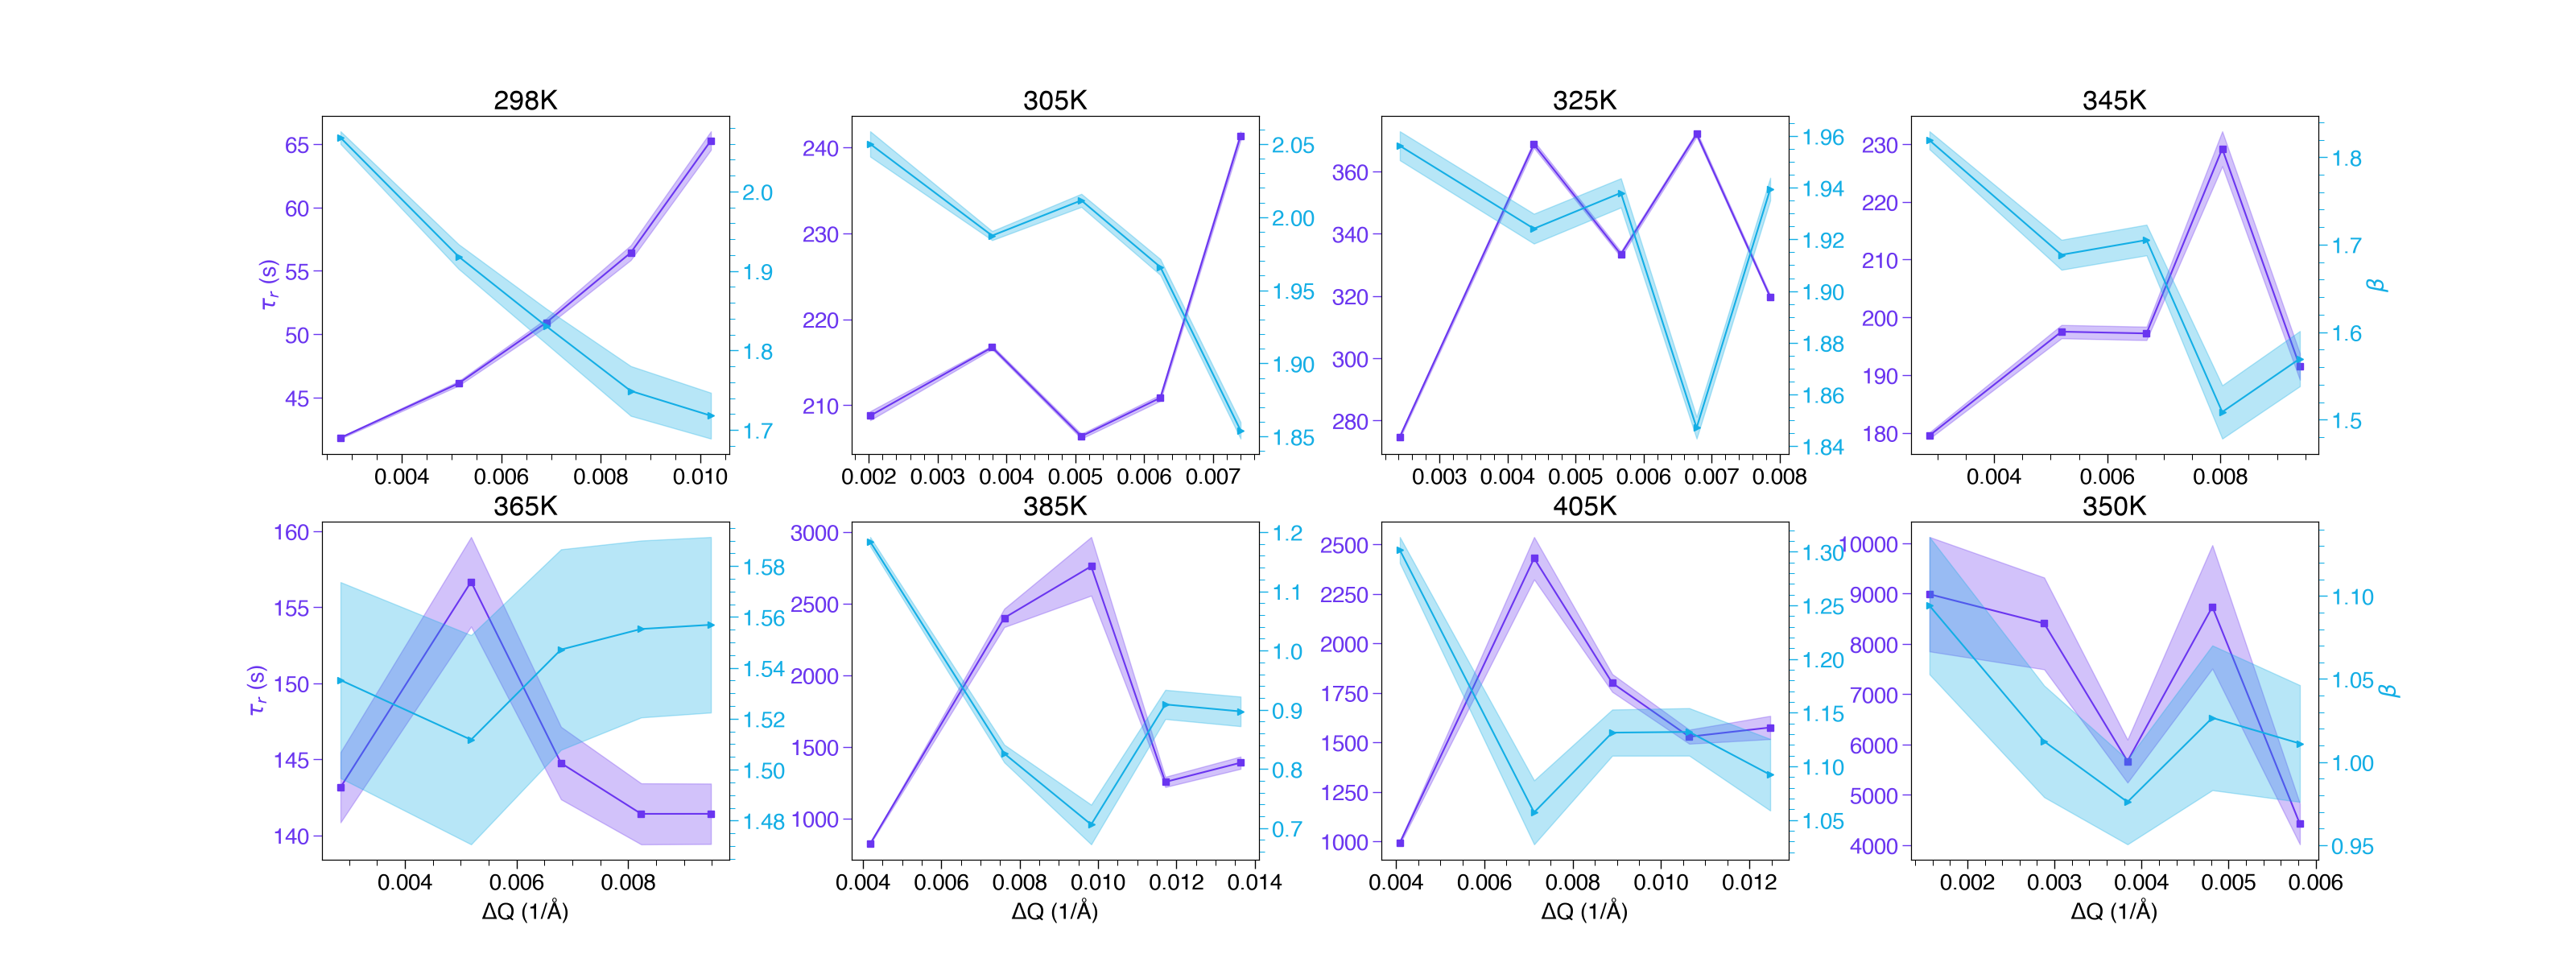

In [6]:
fig, ax = plt.subplots(2,4,figsize=(32,12))
I=0

#tau_color =  '#d54848'        #'#cc5e5e' #'#ce4b5b'
#beta_color = '#373079'   

tau_color =  '#6a35f0'#        #'#cc5e5e' #'#ce4b5b'
beta_color = '#13aee5'   #'#474273' #'#465373'

J=0
for I in range(len(Scans)):
    ax[J,I%4].plot(DQ[I],taus_scan[I],'s-',color=tau_color)    
    ax[J,I%4].fill_between(DQ[I], taus_scan[I] - taus_err_scan[I], taus_scan[I] + taus_err_scan[I], color=tau_color, alpha=0.3)


    # Adjust red y-axis properties
    ax[J,I%4].tick_params(axis='y', colors=tau_color)

    ax[J,I%4].tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=ax_label_font,color=tau_color)
    ax[J,I%4].tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=ax_label_font,color=tau_color)

    ax[J,I%4].tick_params(axis='x',which='major',direction='out',bottom=True, length=major_tick_length, width=major_tick_width, labelsize=ax_label_font,color='k')
    ax[J,I%4].tick_params(axis='x',which='minor',direction='out',bottom=True, length=minor_tick_length, width=minor_tick_width,labelsize=ax_label_font,color='k')

    ax2 = ax[J,I%4].twinx()
    ax2.plot(DQ[I],betas_scan[I],'>-',color=beta_color)    
    ax2.fill_between(DQ[I], betas_scan[I] - betas_err_scan[I], betas_scan[I] + betas_err_scan[I], color=beta_color, alpha=0.3)


    # Adjust blue y-axis properties
    ax2.tick_params(axis='y', colors=beta_color)



    # Adjust red y-axis properties
    ax2.tick_params(axis='y', colors=beta_color)
    ax2.minorticks_on()

    # --- sizes ---
    ax2.tick_params(which='major', length=major_tick_length, width=major_tick_width, labelsize=ax_label_font,color=beta_color)
    ax2.tick_params(which='minor', length=minor_tick_length, width=minor_tick_width,labelsize=ax_label_font,color=beta_color)


    if J==1:
        ax[J,I%4].set_xlabel('$\\Delta$Q (1/Å)',fontsize=ax_label_font)
    if I%4 == 0:
        ax[J,I%4].set_ylabel(r'$\tau_r$ (s)', color=tau_color, fontsize=ax_label_font)
    if I%4 == 3:
        ax2.set_ylabel(r'$\beta$', color=beta_color, fontsize=ax_label_font)

    ax[J,I%4].set_title(f'{Temps[I]}K',fontsize=24)

    if I%4 == 3 and J == 0:
        J=1
fig.subplots_adjust(wspace=0.3)  # Increase the value for more space, decrease for less

fig.savefig(figure_path / f"tau_beta_dependence.pdf", format="pdf", bbox_inches="tight")
